# Ejercicio 03 · Clasificación de sentimiento, embeddings y redes

**INF-8239 · Ciencia de Datos II · Unidad 02 (LAB04, LAB05 y LAB06)**
Estudiante: Emma Carolina Cabrera Valverde

El notebook lee los archivos generados por los scripts del proyecto (`data/processed/` y `reports/`). Para regenerarlos se siguen los comandos del `README.md`.

In [1]:
import json
import re
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REP = ROOT / "reports"
pd.set_option("display.max_colwidth", 110)
df = pd.read_csv(ROOT / "data" / "processed" / "dataset.csv")
df.head()

,text,label,source
0,So there is no way for me to plug it in here in the US unless I go by a converter.,negative,amazon
1,"Good case, Excellent value.",positive,amazon
2,Great for the jawbone.,positive,amazon
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,negative,amazon
4,The mic is great.,positive,amazon


## 1. LAB04 · Auditoría del corpus

In [2]:
text = df["text"].astype(str)
pd.Series({
    "Filas": len(df),
    "Nulos en text / label": f"{df['text'].isna().sum()} / {df['label'].isna().sum()}",
    "Textos duplicados": int(text.duplicated().sum()),
    "Clases": ", ".join(f"{k} {v:.0%}" for k, v in df["label"].value_counts(normalize=True).items()),
    "Longitud p50 / p90 / p99 (caracteres)": " / ".join(str(round(v)) for v in text.str.len().quantile([0.5, 0.9, 0.99])),
}).to_frame("valor")

,valor
Filas,3000
Nulos en text / label,0 / 0
Textos duplicados,18
Clases,"negative 50%, positive 50%"
Longitud p50 / p90 / p99 (caracteres),55 / 121 / 213


In [3]:
pd.crosstab(df["source"], df["label"], margins=True, margins_name="total")

label,negative,positive,total
source,,,
amazon,500,500,1000
imdb,500,500,1000
yelp,500,500,1000
total,1500,1500,3000


El corpus está balanceado por diseño (500 oraciones positivas y 500 negativas por sitio), así que accuracy no engaña como en un corpus desbalanceado. Los 18 duplicados son frases cortas repetidas y se eliminan antes de partir los datos para evitar que la misma oración esté en entrenamiento y prueba.

## 2. LAB05 · Comparación de clasificadores

In [4]:
metrics = pd.read_csv(REP / "text_metrics.csv")
metrics.round(3)

,model,f1_macro,accuracy,recall_negative,recall_positive
0,naive_bayes,0.819,0.819,0.812,0.826
1,logistic,0.788,0.788,0.783,0.794
2,dummy,0.333,0.500,1.000,0.000


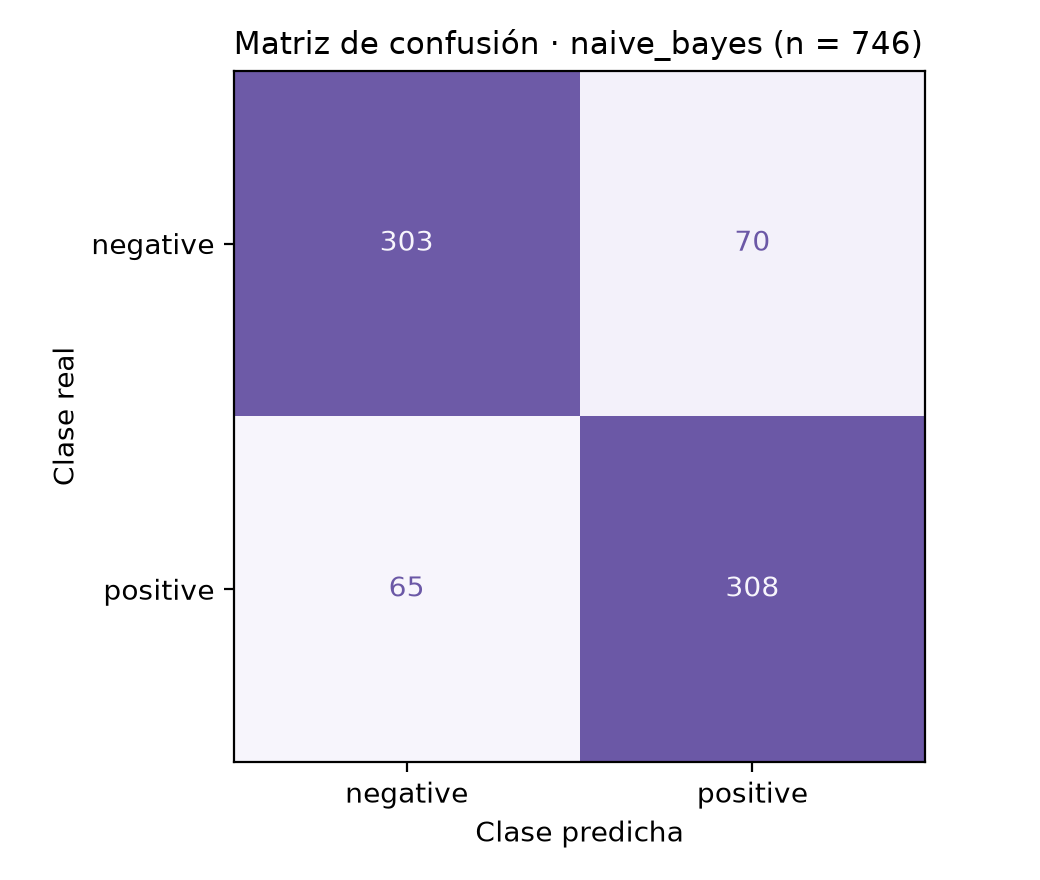

In [5]:
display(Image(REP / "confusion_text.png", width=420))

Naive Bayes obtiene el mejor F1 macro (0.819) y supera a la regresión logística (0.788) en el recall de ambas clases, por eso es el modelo guardado. El error más frecuente son 70 reseñas negativas predichas como positivas: quejas que pasarían desapercibidas.

## 3. LAB05 · 20 errores categorizados

In [6]:
errors = pd.read_csv(REP / "error_analysis.csv")
categorized = pd.read_csv(REP / "error_analysis_categorized.csv")
print("Errores totales:", len(errors), "· revisados:", len(categorized))
categorized[["source", "real", "predicted", "category", "text"]]

Errores totales: 135 · revisados: 20


,source,real,predicted,category,text
0,imdb,positive,negative,Contraste de opiniones,"Totally different, with loads of understatement and black comedy, this is a film few get to see, but those..."
1,imdb,negative,positive,Contraste de opiniones,"But she is still a bad actress, repeating her robotic face moves in each of her pictures."
2,imdb,positive,negative,Contraste de opiniones,"Director Neil LaBute uses brutal violence to seperate dreams from reality, and along with the touching dra..."
3,yelp,negative,positive,Contraste de opiniones,It was a pale color instead of nice and char and has NO flavor.
4,imdb,negative,positive,Ironía,"I felt asleep the first time I watched it, so I can recommend it for insomniacs."
5,yelp,positive,negative,Lenguaje informal,OMG I felt like I had never eaten Thai food until this dish.
6,amazon,negative,positive,Negación,I tried talking real loud but shouting on the telephone gets old and I was still told it wasn't great.
7,imdb,positive,negative,Negación,"The soundtrack wasn't terrible, either."
8,imdb,negative,positive,Negación,i wouldnt see this movie again for free.
9,yelp,positive,negative,Negación,I can't wait to go back.


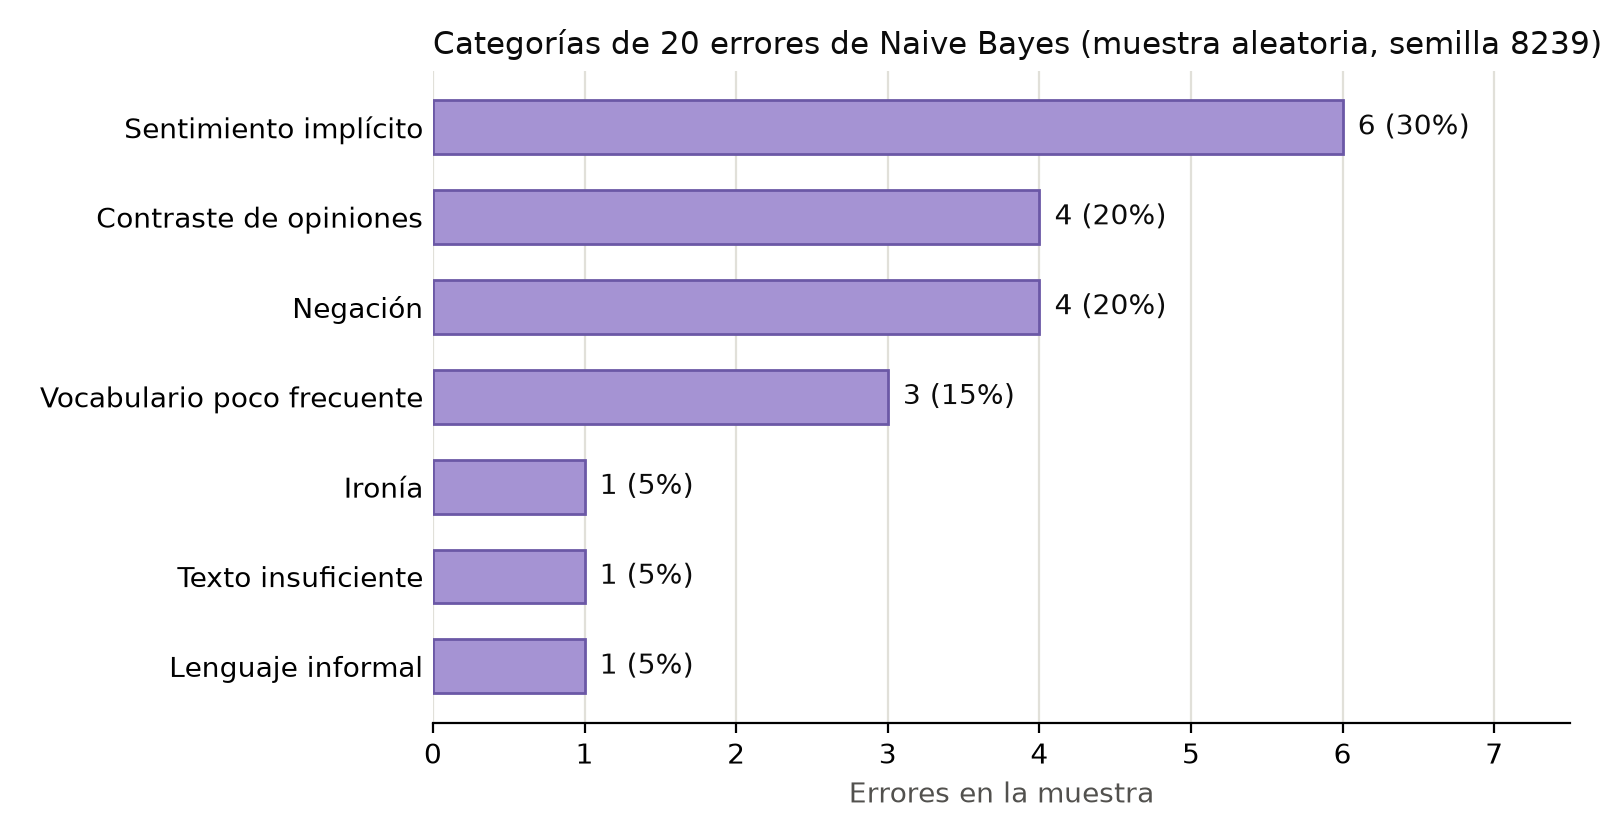

In [7]:
display(Image(REP / "error_categories.png", width=700))

Catorce de los veinte errores (sentimiento implícito, negación y contraste) vienen de que TF-IDF mira palabras sueltas o pares de palabras y no el sentido de la oración. El siguiente experimento sería marcar las palabras negadas o usar un modelo de contexto.

## 4. LAB06 · Embeddings: efecto de `min_count`

In [8]:
rows = []
for path in sorted(REP.glob("word2vec_service_*.json")):
    run = json.loads(path.read_text(encoding="utf-8"))
    rows.append({
        "window": run["window"], "min_count": run["min_count"],
        "vocabulario": run["vocabulary"], "cobertura": run["coverage"],
        "vecinos": ", ".join(n["word"] for n in run["neighbors"]),
    })
pd.DataFrame(rows)

,window,min_count,vocabulario,cobertura,vecinos
0,5,1,5155,1.0000,"impeccable, negligent, food, server, customer, attentive, outstanding, downside, boot, personable"
1,5,3,1468,0.8678,"attentive, friendly, customer, food, staff, server, slow, selection, terrible, extremely"


In [9]:
tokens = [w for s in df["text"] for w in re.findall(r"(?u)\b\w\w+\b", s.lower())]
freq = pd.Series(tokens).value_counts()
pd.Series({w: int(freq.get(w, 0)) for w in ["service", "impeccable", "negligent", "downside", "attentive", "friendly", "slow", "terrible"]}).to_frame("apariciones")

,apariciones
service,108
impeccable,2
negligent,1
downside,1
attentive,7
friendly,29
slow,20
terrible,32


Con `min_count=1` varios vecinos de "service" aparecen una o dos veces en todo el corpus, así que su vector está poco entrenado. Con `min_count=3` el vocabulario se reduce a 1,468 palabras (cobertura 86.8 %) y los vecinos son términos frecuentes del contexto de atención en restaurantes, positivos y negativos: Word2Vec captura el tema, no la polaridad.

## 5. LAB06 · Red de demostración

In [10]:
cent = pd.read_csv(REP / "centralities.csv", index_col="node")
for column in cent.columns:
    cent[f"puesto_{column}"] = cent[column].rank(ascending=False, method="min").astype(int)
cent.loc[[0, 33, 1, 31]].round(3)

,degree,betweenness,pagerank,puesto_degree,puesto_betweenness,puesto_pagerank
node,,,,,,
0,0.485,0.438,0.089,2,1,2
33,0.515,0.304,0.097,1,2,1
1,0.273,0.054,0.057,5,7,5
31,0.182,0.138,0.042,6,5,6


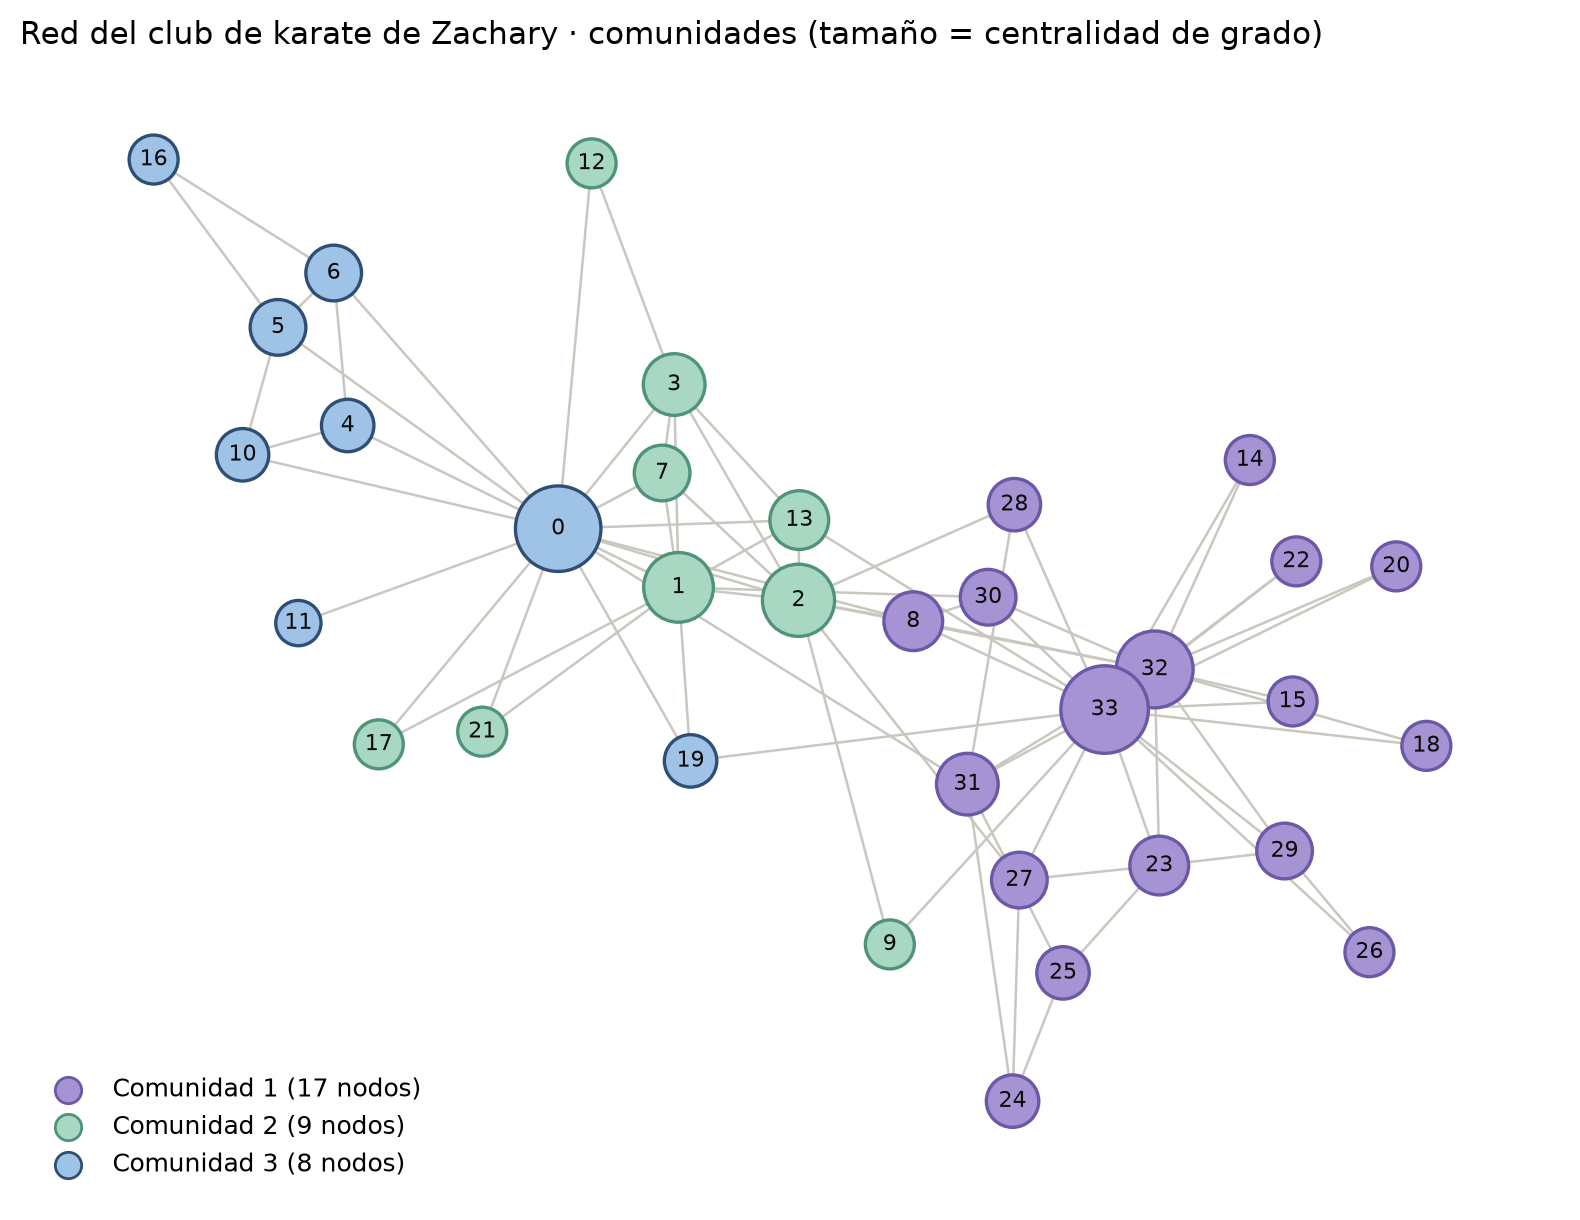

In [11]:
display(Image(REP / "network.png", width=620))

El nodo 31 tiene menos conexiones que el nodo 1, pero más intermediación: actúa como puente entre comunidades. Eso describe su posición en esta red; no demuestra influencia, liderazgo ni causalidad.

## 6. Conclusión
- **LAB04:** corpus público aprobado (UCI, CC BY 4.0), descargado con hash, auditado y documentado en `docs/DATASET_CARD.md`.
- **LAB05:** Naive Bayes es el mejor modelo (F1 macro 0.819). Los errores se concentran en sentimiento implícito, negación y contraste.
- **LAB06:** subir `min_count` reduce el ruido de palabras raras a cambio de cobertura; en la red, grado e intermediación destacan nodos distintos.
- **Límite principal:** solo inglés, tres dominios y oraciones sin opiniones neutrales; el modelo no debe usarse con otras reseñas ni para decidir sobre personas.